# Did the aircraft form a contrail?

For each IAGOS aircraft seen by Sentinel-2, decide whether it formed a contrail, using the manual
`contrail_formation` flag as truth. When it did, segment the contrail in the green band. For now two
priors are used: the **manual aircraft label** (`x`/`y`) and the **aircraft heading** from the CSV.
Later the aircraft detector replaces the manual label.

**Data.** 6 × 6 km chips (600 × 600 px at 10 m) centred on the manual label hold B02, B03, B04 and B10
(cirrus, 60 m, resampled). Where a 6 km window crosses the tile edge, a smaller one is used (4, 3 or 2 km).
The 405 aircraft split into 218 with and 187 without a contrail.

**Physics used.**
- **Direction.** Every plume element drifts with the same wind, so the contrail line points along the
  *air-relative* flight direction: the **heading**, not the ground track. It extends behind the aircraft, at
  heading + 180°. Against the hand-drawn polygons this prior is accurate to a median of ~4° (checked below).
- **Line filter.** A contrail is a thin line: an oriented second-derivative-of-Gaussian ("ridge") filter
  steered along the expected direction responds to it, and isotropic texture does not.
- **Cirrus.** Contrails at ~11 km are bright in B10, the water-vapour absorption band. Roads, rivers and field
  edges, the main line-like clutter in the visible bands, are not.
- **Band offset.** A high line shows up as blue, green and red copies shifted sideways by band-to-band
  parallax. Ground lines are not shifted.
- **Band subtraction.** Green − blue removes background that is equally bright in both bands, above all white
  cloud. A contrail survives because its blue copy is shifted sideways, and its green line remains.
- **Contrast.** pycontrails builds its RGB with CLAHE, a local histogram equalisation (`clip_limit = 0.03`, window
  1/8 of the image). This lifts faint structure inside bright cloud, which is why some contrails look clearer
  in those images than in raw reflectance. The same equalisation is applied to the chip before line filtering.
- **A contrail is straight.** It starts at the aircraft and runs as a thin, straight line along the heading.
  The segmentation is therefore a straight rectangle anchored at the aircraft. A candidate whose response does
  not continue along that straight line (a curved cloud edge, coastline or ridge) is rejected.
- **Detector seams.** Where two Sentinel-2 detectors meet, the aircraft and its contrail can appear twice or
  be offset. Chips near a seam are excluded from the evaluation, with a warning.
- **Aircraft blob.** In B10 the aircraft itself is a 60 m blob, recorded at a slightly different time. Rays
  therefore start 300 m behind the aircraft in B10 (200 m in green), so the aircraft is not mistaken for the
  start of a contrail.

**Evaluation.** Formation precision/recall with the score threshold tuned by granule-level 2-fold
cross-validation. The segmentation is checked against the polygons (`contrail_label`) as a diagnostic.

Code: `src/iagos_toolkit/imagery/contrail_detection.py`, chips from `src/iagos_toolkit/imagery/chips.py`.

In [1]:
import tempfile, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from iagos_toolkit.imagery import contrail_detection as cd
from iagos_toolkit.imagery.chips import add_detector_info, build_chip_cache, load_chips, load_sentinel_collocations

warnings.filterwarnings("ignore", category=RuntimeWarning)
CSV = "../data/landsat_sentinel_collocations_20260216.csv"
CHIP_DIR = Path("../data/contrail_chips")
FIG_DIR = Path("../figures")
csv = pd.read_csv(CSV, comment="#")
INK, MUTED, ACCENT = "#0b0b0b", "#9c9b95", "#2a78d6"


## 1. Chips

Only granules not processed before are downloaded. A window that crosses the tile edge falls back to a smaller size.

In [2]:
df, excluded = load_sentinel_collocations(CSV)
with tempfile.TemporaryDirectory() as tmp:
    for half in (3000, 2000, 1500, 1000):
        have = {int(p.stem[4:8]) for p in CHIP_DIR.glob("pos_*.npz")}
        todo = df[~df.row.isin(have)]
        if half < 3000:  # retry rows whose larger window failed
            for r in todo.row:
                (CHIP_DIR / f".done_{r:04d}").unlink(missing_ok=True)
        build_chip_cache(todo, CHIP_DIR, cache_dir=tmp, n_neg=0, half_size=half, max_workers=6, dtype="float16")
    add_detector_info(df, CHIP_DIR, cache_dir=tmp, max_workers=8)
sizes = pd.Series({p.stem: np.load(p)["x"].size * 10 for p in CHIP_DIR.glob("pos_*.npz")})
print(f"{len(sizes)} aircraft chips; window size (m):", sizes.value_counts().sort_index(ascending=False).to_dict())
print("no chip (tile edge / nodata):", sorted(set(df.row) - {int(n[4:8]) for n in sizes.index}))

405 aircraft chips; window size (m): {6000: 390, 4000: 7, 3000: 5, 2000: 3}
no chip (tile edge / nodata): [426, 534, 576, 680, 754, 755, 761]


## 2. Is the heading a good prior?

The main direction of each labelled polygon is compared with the heading-based direction behind the aircraft.

217 polygons: median |error| 3.8 deg, 90 % within 9.8 deg, reversed (>90 deg): 0


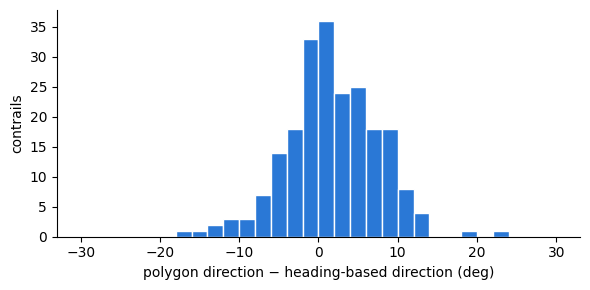

In [3]:
chips2 = cd.attach_metadata([c for c in load_chips(CHIP_DIR) if c["name"] in sizes.index], csv)
err = []
for c in chips2:
    lab = cd.label_mask(c) if c["formation"] else None
    if lab is None or lab.sum() < 5:
        continue
    v, b = cd.mask_direction(lab, cd.aircraft_pixel(c)), cd.behind_direction(c)
    err.append(np.degrees(np.arctan2(v[0] * b[1] - v[1] * b[0], v @ b)))
err = np.asarray(err)
print(f"{len(err)} polygons: median |error| {np.median(np.abs(err)):.1f} deg, 90 % within {np.percentile(np.abs(err), 90):.1f} deg, "
      f"reversed (>90 deg): {(np.abs(err) > 90).sum()}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(err, bins=np.arange(-30, 31, 2), color=ACCENT, edgecolor="white")
ax.set(xlabel="polygon direction − heading-based direction (deg)", ylabel="contrails")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()

## 3. Methods

Each method gives one score per chip. Most use the **angular profile**: the oriented ridge response averaged
along a ray from the aircraft, for every azimuth in 2° steps. Each sample takes the strongest response within
±20 m across the ray. The score is the highest value within ±25° of the expected direction, as a z-score
against the directions more than 40° away. It measures how much "behind the aircraft" stands out from all
other directions.

| method | what it measures |
|---|---|
| `corridor` | baseline: mean \|green top-hat\| in a 100 m wide strip, 200 m–1 km behind, z-scored against 36 other directions |
| `green` | green angular profile, bright lines, σ = 10 m, 200 m–1 km |
| `green_s2` | as above with σ = 20 m (wider, older contrails) |
| `green_minus_blue_raw` | the same profile on B03 − B02 |
| `green_minus_maxbr` | the same profile on B03 − max(B02, B04) |
| `green_minus_blue` | the same profile on CLAHE(B03) − CLAHE(B02) |
| `rgb_min` | band-offset test: the line's strength in the *weakest* of B02/B03/B04, each band allowed its own sideways offset of up to ±120 m |
| `cirrus_raw` | B10 angular profile, σ = 30 m, 300 m–1 km, bright or dark |
| `cirrus_s6` | as above with σ = 60 m |
| `cirrus` | the B10 profile after CLAHE, 200 m–1 km, bright lines |
| `combined_v1` | first version: log(1 + cirrus_raw) + 0.25 · log(1 + green) |
| `combined` | log(1 + cirrus) + 0.5 · log(1 + green_minus_blue) |
| **`final`** | **`combined`, but only where the straight line from the aircraft is continuous (≥ 40 % of 150 m–1 km); chips near a detector seam excluded** |

Start distance, length, scale, polarity, contrast settings and weights were swept with the same
cross-validation. A short segment up to 1 km works best: most contrails are clearest close to the aircraft,
and longer rays add cloud texture. Because many settings were compared, the choice was also checked with
**nested** cross-validation, where the method and weight are chosen on one half only. That gives P 0.94 /
R 0.94 for the new images, against 0.91 / 0.91 for the first version.

The table averages 2-fold cross-validation over 5 random granule splits, on the chips that are not near a
detector seam.

**Straight-line model.** The contrail is fitted as a straight line anchored at the aircraft:
1. **Direction:** the cirrus direction, refined within ±6° on the green − blue ridge response.
2. **Length:** the line ends where the smoothed response (200 m) stays below z = 1 for more than 200 m.
3. **Width:** the half-maximum width of the cross-track profile, 20–150 m.

The **continuity** of that line, the share of 150 m–1 km behind the aircraft with a response, is the
straightness test. Requiring ≥ 40 % removes candidates that only touch the line here and there.

A second measure, the share of a freely grown outline that falls inside the rectangle, was also tested. It
removed too many real contrails (recall 0.90), because cloud texture makes the free outline ragged even around
straight contrails.

In [4]:
feat = cd.run_features(CHIP_DIR, csv)
lines = cd.run_line_fits(CHIP_DIR, csv, dict(zip(feat.chip, feat.cirrus_az)))
feat = feat.merge(lines, on="chip")
feat["final"] = cd.final_score(feat)
all_chips = feat.copy()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    feat = cd.flag_seams(feat)  # chips near a detector seam: excluded from here on
for w in caught:
    print("WARNING:", w.message)
print()
METHODS = ["corridor", "green", "green_s2", "green_minus_blue_raw", "green_minus_maxbr", "green_minus_blue",
           "rgb_min", "cirrus_raw", "cirrus_s6", "cirrus", "combined_v1", "combined", "final"]
rows = []
for m in METHODS:
    cv = pd.concat([cd.cross_validate_binary(feat, m, seed=k) for k in range(5)])
    rows.append({"method": m, "CV precision": cv.precision.mean(), "CV recall": cv.recall.mean(),
                 "worst fold P": cv.precision.min(), "worst fold R": cv.recall.min(), "median τ": cv.threshold.median()})
summary = pd.DataFrame(rows).set_index("method").round(3)
for name, d in (("all chips, incl. seams", all_chips), ("seams excluded", feat)):
    cv = pd.concat([cd.cross_validate_binary(d, "final", seed=k) for k in range(5)])
    print(f"final, {name}: P {cv.precision.mean():.3f}  R {cv.recall.mean():.3f}  ({len(d)} chips)")
summary


final, all chips, incl. seams: P 0.968  R 0.954  (405 chips)
final, seams excluded: P 0.981  R 0.956  (384 chips)


,CV precision,CV recall,worst fold P,worst fold R,median τ
method,,,,,
corridor,0.684,0.683,0.630,0.540,1.450
green,0.789,0.772,0.730,0.679,2.916
green_s2,0.751,0.757,0.684,0.717,2.865
green_minus_blue_raw,0.875,0.868,0.815,0.826,4.884
green_minus_maxbr,0.873,0.874,0.798,0.835,4.272
green_minus_blue,0.907,0.881,0.813,0.832,4.332
rgb_min,0.792,0.788,0.730,0.664,0.940
cirrus_raw,0.904,0.916,0.889,0.891,3.819
cirrus_s6,0.854,0.859,0.788,0.817,3.170


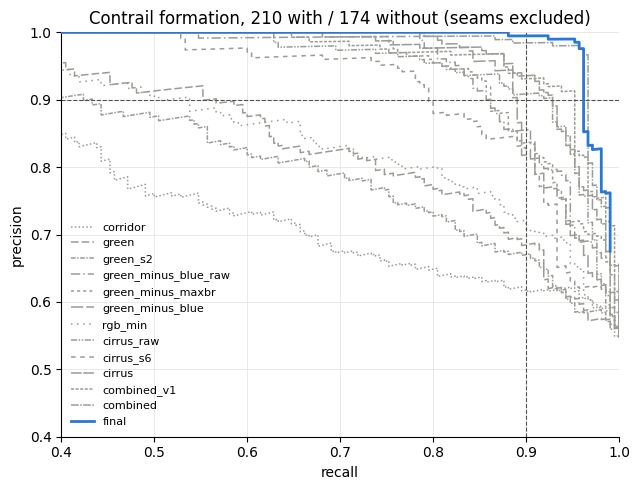

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 5))
styles = iter([(0, (1, 1.5)), (0, (5, 2)), (0, (3, 1, 1, 1)), (0, (6, 2, 1, 2)), (0, (2, 2)), (0, (8, 2)),
               (0, (1, 3)), (0, (4, 1, 1, 1, 1, 1)), (0, (3, 3)), (0, (7, 1)), (0, (2, 1)), (0, (5, 1, 1, 1))])
for m in METHODS:
    pr = cd.binary_pr(feat[m].to_numpy(float), feat.formation.to_numpy())
    pr = pr[np.isfinite(pr.threshold)]
    final = m == "final"
    ax.plot(pr.recall, pr.precision, color=ACCENT if final else MUTED, lw=2 if final else 1.1,
            ls="-" if final else next(styles), label=m, zorder=3 if final else 2)
ax.axhline(0.9, color="#52514e", lw=0.8, ls="--"); ax.axvline(0.9, color="#52514e", lw=0.8, ls="--")
ax.set(xlim=(0.4, 1), ylim=(0.4, 1.0), xlabel="recall", ylabel="precision",
       title=f"Contrail formation, {feat.formation.sum()} with / {(~feat.formation).sum()} without (seams excluded)")
ax.grid(color="#e6e5e0", lw=0.6); ax.set_axisbelow(True); ax.legend(loc="lower left", fontsize=8, frameon=False)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "contrail_formation_pr.png", dpi=300)

### What the new input images show

Two contrails that the first version missed and the final score finds. Blue-subtracted and contrast-equalised
images bring out the line inside cloud and haze. The heading prior is the yellow arrow, the labelled polygon cyan.

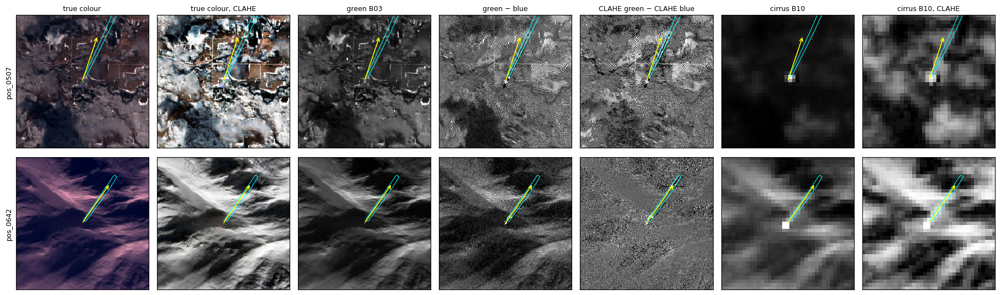

In [6]:
def stretch(a):
    lo, hi = np.nanpercentile(a, [1, 99.8]); return np.clip((a - lo) / max(hi - lo, 1e-9), 0, 1)

by_name = {c["name"]: c for c in chips2}
panels = [("true colour", lambda c: stretch(np.dstack([c["B04"], c["B03"], c["B02"]]).astype("float32"))),
          ("true colour, CLAHE", lambda c: np.dstack([cd.clahe(c[b]) for b in ("B04", "B03", "B02")])),
          ("green B03", lambda c: stretch(cd.image(c, "B03"))),
          ("green − blue", lambda c: stretch(cd.image(c, "g_minus_b"))),
          ("CLAHE green − CLAHE blue", lambda c: stretch(cd.image(c, "g_minus_b_clahe"))),
          ("cirrus B10", lambda c: stretch(cd.image(c, "B10"))),
          ("cirrus B10, CLAHE", lambda c: stretch(cd.image(c, "B10_clahe")))]
examples = ["pos_0507", "pos_0642"]
fig, ax = plt.subplots(len(examples), len(panels), figsize=(2.6 * len(panels), 2.8 * len(examples)), squeeze=False)
for i, n in enumerate(examples):
    c = by_name[n]; o, b = cd.aircraft_pixel(c), cd.behind_direction(c); lab = cd.label_mask(c)
    h = 110
    for j, (title, fn) in enumerate(panels):
        a = ax[i, j]; img = fn(c)
        a.imshow(img, cmap=None if img.ndim == 3 else "gray", interpolation="nearest")
        if lab is not None and lab.any():
            a.contour(lab, [0.5], colors="cyan", linewidths=0.7)
        a.annotate("", xy=(o[1] + b[1] * 80, o[0] + b[0] * 80), xytext=(o[1], o[0]), arrowprops=dict(arrowstyle="->", color="yellow", lw=1.2))
        a.set_xlim(o[1] - h, o[1] + h); a.set_ylim(o[0] + h, o[0] - h); a.set_xticks([]); a.set_yticks([])
        if i == 0:
            a.set_title(title, fontsize=9)
    ax[i, 0].set_ylabel(n, fontsize=9)
fig.tight_layout(); fig.savefig(FIG_DIR / "contrail_input_images.png", dpi=120)

## 4. Operating point and where it fails

In [7]:
best = cd.best_binary_threshold(feat.final, feat.formation)
TAU = best["threshold"]
feat["pred"] = feat.final >= TAU
feat["outcome"] = np.select([feat.formation & feat.pred, feat.formation, feat.pred], ["TP", "FN", "FP"], "TN")
print(f"pooled τ = {TAU:.2f}: precision {best['precision']:.3f}, recall {best['recall']:.3f}")
b1 = cd.best_binary_threshold(feat.combined_v1, feat.formation); p1 = feat.combined_v1 >= b1["threshold"]
print(f"vs first version: fixes {(feat.formation & ~p1 & feat.pred).sum()} misses and {(~feat.formation & p1 & ~feat.pred).sum()} false alarms, "
      f"adds {(feat.formation & p1 & ~feat.pred).sum()} misses and {(~feat.formation & ~p1 & feat.pred).sum()} false alarms")
print(feat.outcome.value_counts().to_string())
print("rejected by the straightness rule (continuity < 0.4) although combined ≥ τ:",
      dict(feat[(feat.combined >= TAU) & ~feat.pred].formation.value_counts().rename({True: "contrail", False: "no contrail"})))
feat["background"] = np.where(feat.b10_background > 0.01, "cloudy (B10 > 0.01)", "clear")
feat["label length"] = pd.cut(feat.label_length_m, [0, 1000, 3000, 1e9], labels=["< 1 km", "1–3 km", "> 3 km"])
def pr_by(g):
    tp = (g.formation & g.pred).sum()
    return pd.Series({"chips": len(g), "with contrail": int(g.formation.sum()),
                      "precision": tp / max(g.pred.sum(), 1), "recall": tp / max(g.formation.sum(), 1)})
display(feat.groupby("background").apply(pr_by).round(3))
display(feat[feat.formation].groupby("label length", observed=True).apply(lambda g: pd.Series({"contrails": len(g), "recall": g.pred.mean()})).round(3))

pooled τ = 2.20: precision 0.976, recall 0.962
vs first version: fixes 10 misses and 15 false alarms, adds 2 misses and 4 false alarms
outcome
TP    202
TN    169
FN      8
FP      5
rejected by the straightness rule (continuity < 0.4) although combined ≥ τ: {'no contrail': np.int64(2), 'contrail': np.int64(1)}


/var/folders/zt/t69lkpcs0mz7l5vz3jt_48ldzb8s6f/T/ipykernel_91013/2212369706.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(feat.groupby("background").apply(pr_by).round(3))


,chips,with contrail,precision,recall
background,,,,
clear,234.0,119.0,0.967,0.983
cloudy (B10 > 0.01),150.0,91.0,0.988,0.934


/var/folders/zt/t69lkpcs0mz7l5vz3jt_48ldzb8s6f/T/ipykernel_91013/2212369706.py:19: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(feat[feat.formation].groupby("label length", observed=True).apply(lambda g: pd.Series({"contrails": len(g), "recall": g.pred.mean()})).round(3))


,contrails,recall
label length,,
< 1 km,43.0,0.907
1–3 km,89.0,0.966
> 3 km,77.0,1.000


## 5. Segmentation

For every chip predicted to have a contrail, the segment is the **straight rectangle** of the line model
(section 3). It runs from the aircraft along the refined direction, with the fitted length and width, on the
green − blue ridge response:
- **Why green − blue:** it removes the white cloud background.
- **Why a rectangle:** a contrail is a straight line from the aircraft, so the segment cannot follow curved
  cloud edges.
- **Length:** short contrails end where the line fades; long ones run to the chip edge.

Checked against the labelled polygons with a 30 m tolerance:
- **coverage:** the share of the polygon covered by the segment
- **precision:** the share of the segment inside the polygon

rectangle found for 100% of the 202 correctly detected contrails; segment length / labelled length: median 0.97


,coverage,seg_precision,line_length_m,label_length_m,line_width_m
count,202.00,202.00,202.00,202.00,202.00
mean,0.67,0.84,1777.62,2210.02,32.08
std,0.30,0.19,824.60,1105.87,12.95
min,0.00,0.00,320.00,324.04,20.00
25%,0.41,0.74,1150.00,1101.27,20.00
50%,0.75,0.92,1550.00,2254.88,30.00
75%,0.97,0.98,2360.00,3127.72,40.00
max,1.00,1.00,4040.00,4235.35,70.00


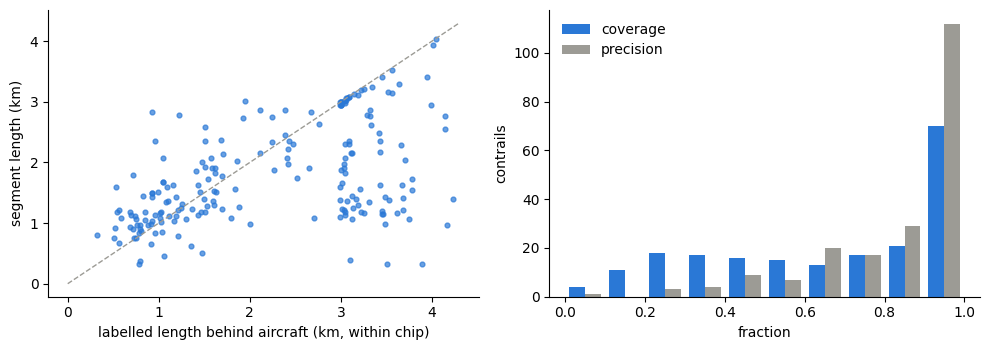

In [8]:
tp = feat[feat.outcome == "TP"]
print(f"rectangle found for {(tp.line_length_m > 0).mean():.0%} of the {len(tp)} correctly detected contrails; "
      f"segment length / labelled length: median {(tp.line_length_m / tp.label_length_m).median():.2f}")
display(tp[["coverage", "seg_precision", "line_length_m", "label_length_m", "line_width_m"]].describe(percentiles=[.25, .5, .75]).round(2))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(tp.label_length_m / 1000, tp.line_length_m / 1000, s=12, color=ACCENT, alpha=0.7)
ax[0].plot([0, 4.3], [0, 4.3], color=MUTED, lw=1, ls="--")
ax[0].set(xlabel="labelled length behind aircraft (km, within chip)", ylabel="segment length (km)")
ax[1].hist([tp.coverage.dropna(), tp.seg_precision.dropna()], bins=np.linspace(0, 1, 11), label=["coverage", "precision"],
           color=[ACCENT, MUTED])
ax[1].set(xlabel="fraction", ylabel="contrails"); ax[1].legend(frameon=False)
for a in ax:
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "contrail_segmentation_diagnostics.png", dpi=200)

## 6. Galleries

Each chip shows:
- **Full chip:** true colour with the labelled polygon (cyan), the straight segment (red), the freely grown
  outline used for the straightness check (orange, dashed), the heading prior (yellow arrow, 1.5 km) and
  detector seams (white).
- **2 km zoom** with the same overlays.
- **CLAHE green − CLAHE blue**, with the measured cirrus direction (magenta).
- **The cirrus angular profile** (after CLAHE): z per azimuth, the ±25° search window shaded, the measured direction marked
  and τ for comparison.

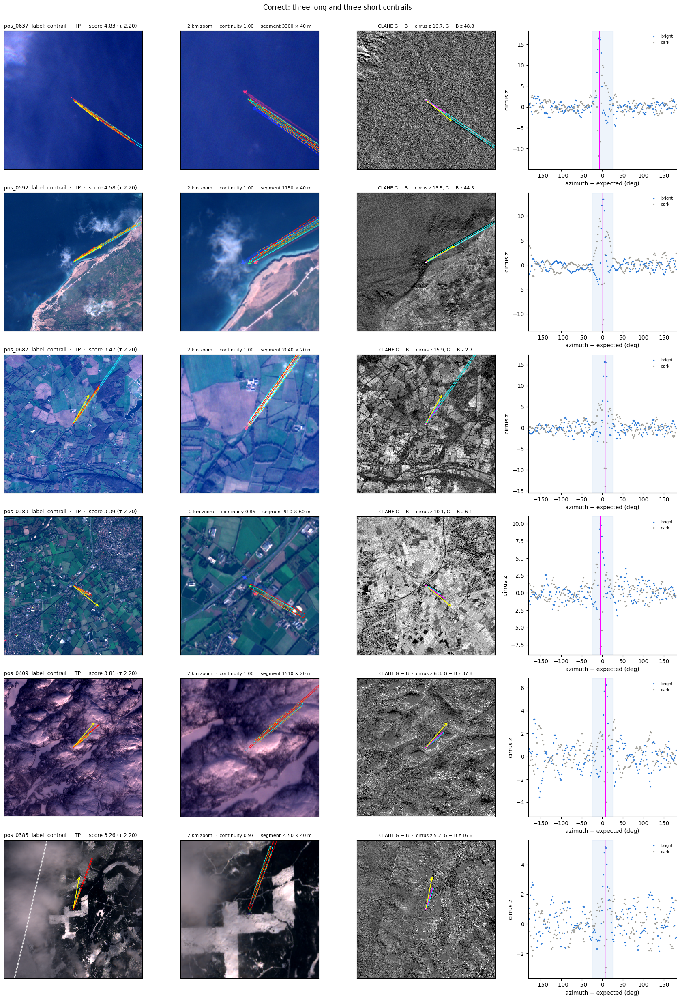

In [9]:
def gallery(names, title, path=None, table=None):
    table = feat if table is None else table
    names = list(names)
    if not names:
        print("nothing to show"); return
    fig, axes = plt.subplots(len(names), 4, figsize=(17, 4.1 * len(names)), squeeze=False)
    for k, n in enumerate(names):
        c, s = by_name[n], table.set_index("chip").loc[n]
        o, b = cd.aircraft_pixel(c), cd.behind_direction(c)
        H, W = c["B03"].shape
        rgb = stretch(np.dstack([c["B04"], c["B03"], c["B02"]]).astype("float32"))
        fit = cd.fit_contrail_line(c, s.cirrus_az)
        seg = fit["mask"] if s.pred else np.zeros((H, W), bool)
        lab = cd.label_mask(c)
        h = 100
        r0, r1, c0, c1 = max(o[0] - h, 0), min(o[0] + h, H), max(o[1] - h, 0), min(o[1] + h, W)
        t = np.deg2rad(s.cirrus_az)
        for a, (img, cm, win) in zip(axes[k, :3], [(rgb, None, None), (rgb, None, (r0, r1, c0, c1)), (stretch(cd.image(c, "g_minus_b_clahe")), "gray", None)]):
            a.imshow(img, cmap=cm, interpolation="nearest")
            if lab is not None and lab.any():
                a.contour(lab, [0.5], colors="cyan", linewidths=0.9)
            if seg.any() and a is not axes[k, 2]:
                a.contour(seg, [0.5], colors="red", linewidths=0.9)
            if fit["free_mask"].any() and a is not axes[k, 2]:
                a.contour(fit["free_mask"], [0.5], colors="orange", linewidths=0.6, linestyles="dashed")
            if "det_border_m" in c and c["det_border_m"].min() < 10 and a is axes[k, 0]:
                a.contour(c["det_border_m"], [10.5], colors="white", linewidths=0.6)
            a.annotate("", xy=(o[1] + b[1] * 150, o[0] + b[0] * 150), xytext=(o[1], o[0]), arrowprops=dict(arrowstyle="->", color="yellow", lw=1.4))
            if a is axes[k, 2]:
                a.plot([o[1], o[1] + np.sin(t) * 100], [o[0], o[0] - np.cos(t) * 100], color="magenta", lw=1.4)
            if win:
                a.set_xlim(win[2], win[3]); a.set_ylim(win[1], win[0])
            else:
                a.set_xlim(0, W); a.set_ylim(H, 0)
            a.set_xticks([]); a.set_yticks([])
        prof = cd.angular_profile(cd.image(c, cd.CIRRUS["image"]), o, cd.CIRRUS["sigma"], r0=cd.CIRRUS["r0"], lengths=(cd.CIRRUS["length"],))
        ang = prof["angles"]; diff = (ang - s.expected_az + 180) % 360 - 180
        for pol, col in (("bright", ACCENT), ("dark", MUTED)):
            p = prof[pol][:, 0]; ref = p[np.abs(diff) > 40]; med = np.nanmedian(ref); mad = 1.4826 * np.nanmedian(np.abs(ref - med))
            axes[k, 3].plot(diff, (p - med) / max(mad, 1e-9), ".", ms=3, color=col, label=pol)
        axes[k, 3].axvspan(-25, 25, color=ACCENT, alpha=0.08)
        axes[k, 3].axvline((s.cirrus_az - s.expected_az + 180) % 360 - 180, color="magenta", lw=1)
        axes[k, 3].set(xlim=(-180, 180), xlabel="azimuth − expected (deg)", ylabel="cirrus z")
        axes[k, 3].legend(frameon=False, fontsize=7, loc="upper right")
        for sp in ("top", "right"):
            axes[k, 3].spines[sp].set_visible(False)
        axes[k, 0].set_title(f"{n}  label: {'contrail' if s.formation else 'none'}  ·  {s.get('outcome', 'seam')}  ·  score {s.combined:.2f} (τ {TAU:.2f})", fontsize=9, loc="left")
        axes[k, 1].set_title(f"2 km zoom  ·  continuity {s.continuity:.2f}" + (f"  ·  segment {s.line_length_m:.0f} × {s.line_width_m:.0f} m" if s.pred else ""), fontsize=8)
        axes[k, 2].set_title(f"CLAHE G − B  ·  cirrus z {s.cirrus:.1f}, G − B z {s.green_minus_blue:.1f}", fontsize=8)
    fig.suptitle(title, y=1.0); fig.tight_layout()
    if path:
        fig.savefig(path, dpi=60, bbox_inches="tight")

rng = np.random.default_rng(0)
tps = feat[feat.outcome == "TP"]
long_ = tps[tps.label_length_m > 3000].chip; short = tps[tps.label_length_m < 1000].chip
gallery(list(rng.choice(long_, 3, replace=False)) + list(rng.choice(short, 3, replace=False)),
        "Correct: three long and three short contrails", FIG_DIR / "contrail_hits.png")

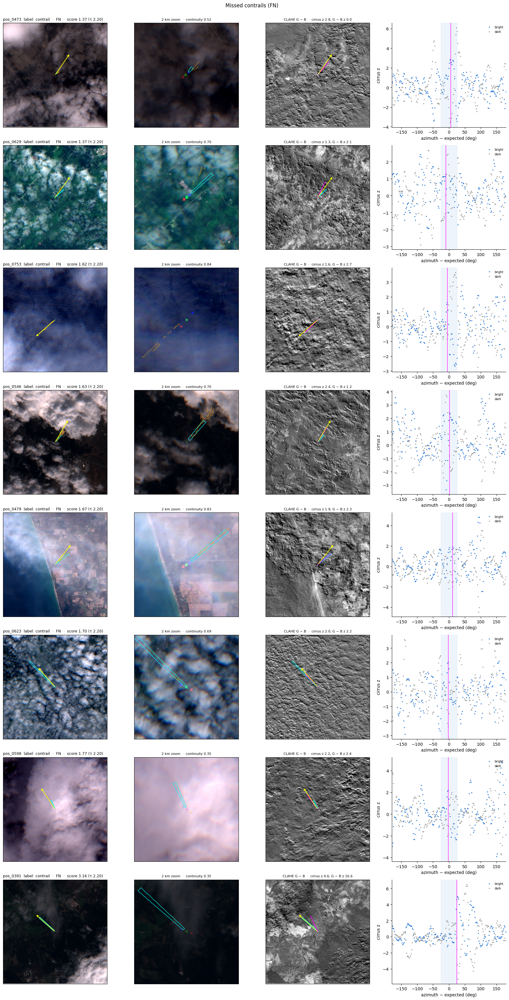

In [10]:
gallery(feat[feat.outcome == "FN"].sort_values("combined").chip, "Missed contrails (FN)", FIG_DIR / "contrail_misses.png")

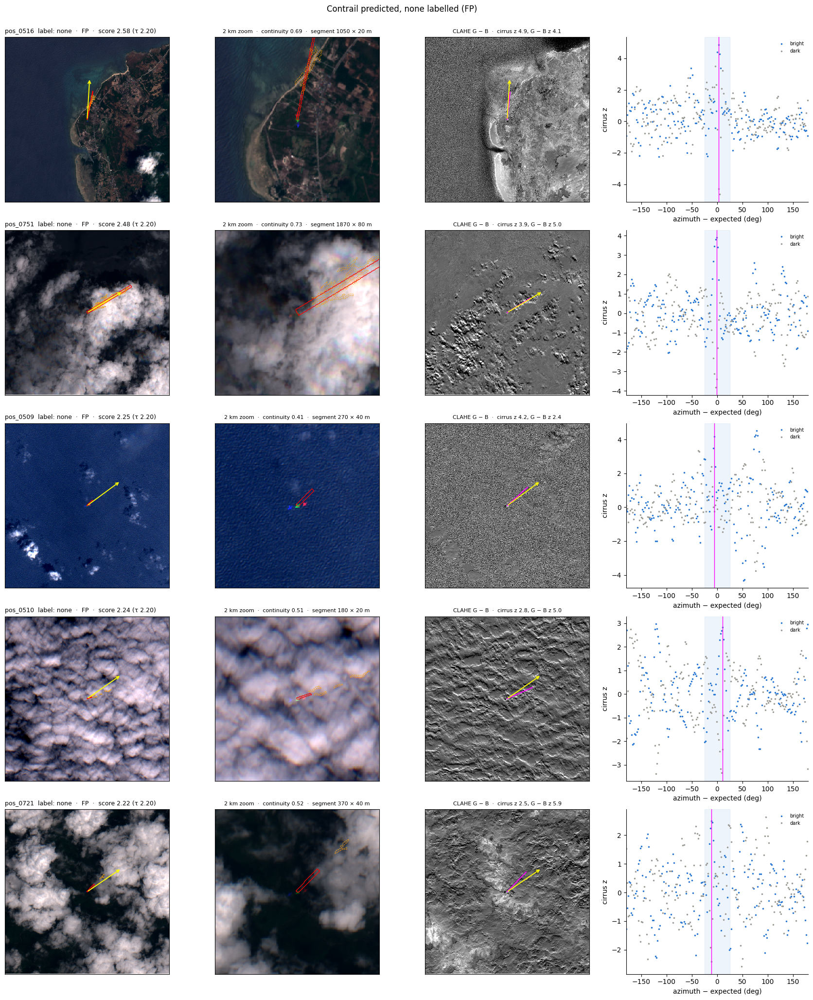

In [11]:
gallery(feat[feat.outcome == "FP"].sort_values("combined", ascending=False).chip, "Contrail predicted, none labelled (FP)", FIG_DIR / "contrail_false_alarms.png")

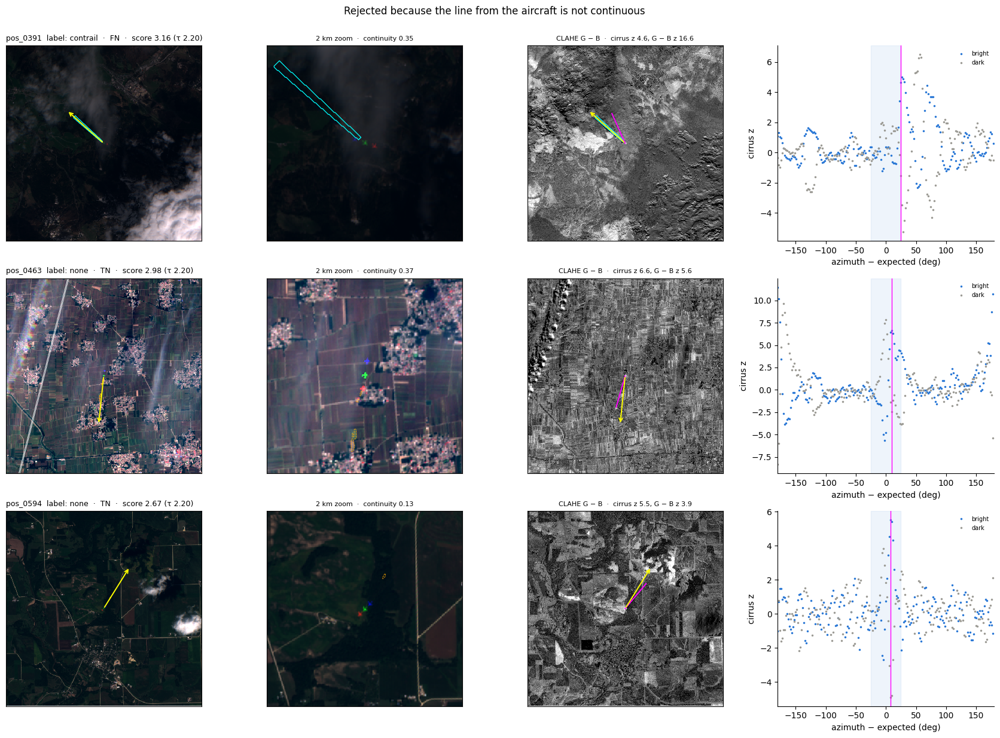

In [12]:
# rejected by the straightness rule: would have been accepted on the score alone
gallery(feat[(feat.combined >= TAU) & ~feat.pred].sort_values("combined", ascending=False).chip,
        "Rejected because the line from the aircraft is not continuous", FIG_DIR / "contrail_straightness_rejected.png")

    chip  formation                                                                                          seam_reason
pos_0366       True               aircraft 215 m from a detector seam; seam crosses the contrail path (detectors [8, 9])
pos_0376      False                                                    seam crosses the contrail path (detectors [4, 5])
pos_0380      False                                                    seam crosses the contrail path (detectors [4, 5])
pos_0393       True                                                    seam crosses the contrail path (detectors [5, 6])
pos_0419      False seam crosses the contrail path (detectors [9, 10]); aircraft duplicated 457 m away on detectors 9|10
pos_0446      False                aircraft 41 m from a detector seam; seam crosses the contrail path (detectors [2, 3])
pos_0459       True                                                   seam crosses the contrail path (detectors [9, 10])
pos_0482       True             

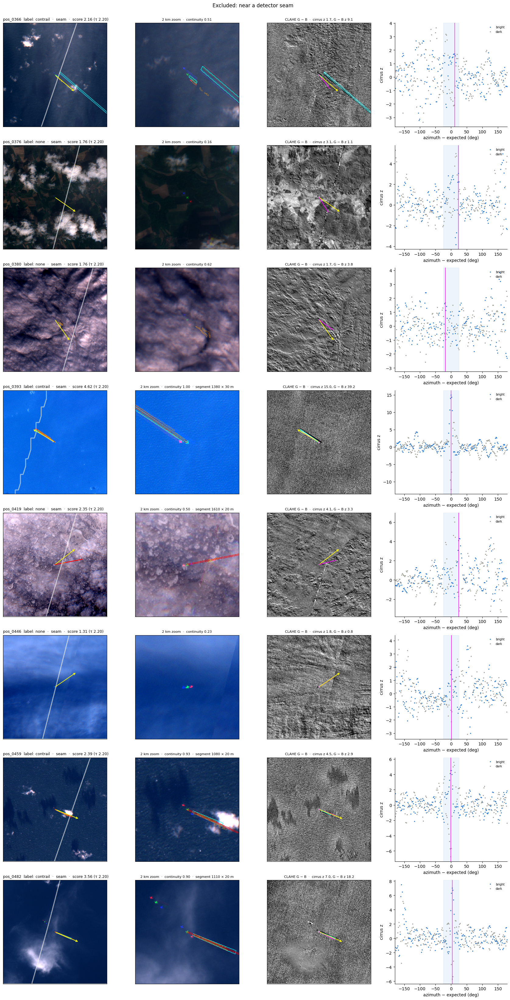

In [13]:
# excluded chips near a detector seam (white lines); their result should not be used
seam = all_chips[all_chips.near_seam].assign(pred=lambda d: d.final >= TAU, outcome="seam")
print(seam[["chip", "formation", "seam_reason"]].to_string(index=False))
gallery(seam.chip.head(8), "Excluded: near a detector seam", FIG_DIR / "contrail_seams.png", table=seam)

## 7. Error audit (by eye, τ ≈ 2.2, seams excluded)

- **Band subtraction made the visible bands useful.**
  - Plain green is a weak detector (P/R ≈ 0.77): roads, rivers, field edges and cloud texture are as line-like
    as contrails.
  - Subtracting blue removes white cloud and most clutter (green − blue: 0.87). The pycontrails-style
    contrast equalisation (CLAHE) lifts this to 0.91 / 0.88.
  - Combined with the equalised cirrus line, the score reaches P 0.955 / R 0.955 on all chips.
- **Straight segments.** A contrail starts at the aircraft and is a straight, thin line, so it is segmented as a
  rectangle anchored at the aircraft. The direction is refined within ±6°; the length runs to where the
  smoothed line response fades; the width is the half-maximum width, median 30 m.
  - The rectangle's median length matches the labelled length (ratio 0.97).
  - It covers a median 75% of the labelled polygon, at 92% precision.
  - Curved outlines along clouds or coasts can no longer occur.
- **Straightness rule.** A candidate is only a contrail if the ridge response is continuous along the straight
  line from the aircraft: at least 40% of 150 m–1 km.
  - It removes straight-looking but broken clutter: a road (`pos_0594`) and field edges (`pos_0463`).
  - It loses one real contrail (`pos_0391`), where the cirrus direction was ~25° off the actual contrail.
  - Measuring straightness as the share of a freely grown outline that falls inside the rectangle removed too
    many real contrails (recall 0.90), because cloud texture makes the free outline ragged.
- **Detector seams (21 chips excluded with a warning).** Excluded when the aircraft is within 250 m of a seam,
  when a seam crosses the first 1.5 km of the contrail path, or when the aircraft detector finds a duplicated
  aircraft (6 chips, all on neighbouring detectors). This removed false alarms such as the duplicated aircraft
  `pos_0419` and the snow ridge `pos_0648`, and the contrail `pos_0366`, which is offset across a seam.
- **Remaining false alarms (5).**
  - A straight coastline exactly along the heading (`pos_0516`): the one case the straightness rule cannot
    reject.
  - Cloud edges in cumulus fields (`pos_0751`, `pos_0510`, `pos_0721`).
  - Ocean texture (`pos_0509`).
- **Remaining misses (8).** Faint, short contrails inside cumulus fields or haze, where no line stands out in any
  image.
- **Caveat on tuning.** Many settings were compared on these 384 chips. The nested estimate for the score
  without the straightness rule was P 0.94 / R 0.94; the straightness rule and seam exclusion were each
  checked with the same 2-fold cross-validation.

**Bottom line.** On the 384 chips not affected by a detector seam, `final` (log(1 + cirrus z after CLAHE)
+ 0.5 · log(1 + green − blue z after CLAHE), accepted only when the straight line from the aircraft is
continuous) reaches precision 0.981 and recall 0.956 for contrail formation (2-fold CV over 5 splits; worst
fold 0.97 / 0.95; pooled τ ≈ 2.2: P 0.976, R 0.962). On all 405 chips including seams it is P 0.968 / R 0.954.